# PowerCo: khách hàng rời bỏ có phải vì giá? (BCG X case study)

Bối cảnh: PowerCo là công ty cung cấp điện và gas cho khách hàng doanh nghiệp vừa và nhỏ (SME) ở châu Âu. Thị trường năng lượng vừa được tự do hóa nên khách dễ chuyển sang nhà cung cấp khác. PowerCo cho rằng khách rời đi vì **nhạy cảm về giá**, và đang cân nhắc **giảm giá 20%** cho những khách có nguy cơ rời đi.

Câu hỏi cần trả lời:
1. Tỷ lệ churn là bao nhiêu, ai đang rời đi?
2. Giả thuyết "khách rời đi vì giá" có đúng không?
3. Có dự đoán được khách sắp rời đi không, và giảm giá 20% có đáng không?

Dữ liệu (từ BCG X Virtual Experience trên Forage):
- `client_data.csv`: 14.606 khách, thông tin hợp đồng, mức tiêu thụ, biên lợi nhuận, và cột `churn` (khách rời đi trong 3 tháng đầu năm 2016)
- `price_data.csv`: giá điện theo tháng của từng khách trong năm 2015

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
os.makedirs('figures', exist_ok=True)

BLUE = '#197A56'
MINT = '#29BA74'
GREY = '#C9D3CE'

## 1. Đọc dữ liệu

Nếu chạy trên Google Colab: bấm Run all, đến ô dưới sẽ hiện nút **Choose Files**, chọn **cả hai** file `client_data.csv` và `price_data.csv`.

In [2]:
if os.path.exists('data/client_data.csv'):
    folder = 'data/'
elif os.path.exists('client_data.csv'):
    folder = ''
else:   # chạy trên Colab thì tải file lên
    from google.colab import files
    files.upload()
    folder = ''

client = pd.read_csv(folder + 'client_data.csv')
price = pd.read_csv(folder + 'price_data.csv')
print('client:', client.shape)
print('price: ', price.shape)
client.head()

client: (14606, 26)
price:  (193002, 8)


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,15-06-2013,15-06-2016,01-11-2015,23-06-2015,0.00,...,t,0.00,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,21-08-2009,30-08-2016,21-08-2009,31-08-2015,189.95,...,f,0.00,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,16-04-2010,16-04-2016,16-04-2010,17-04-2015,47.96,...,f,0.00,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,30-03-2010,30-03-2016,30-03-2010,31-03-2015,240.04,...,f,0.00,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,13-01-2010,07-03-2016,13-01-2010,09-03-2015,445.75,...,f,52.32,44.91,44.91,1,47.98,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0


In [3]:
client.info()

<class 'pandas.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  str    
 1   channel_sales                   14606 non-null  str    
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  str    
 6   date_end                        14606 non-null  str    
 7   date_modif_prod                 14606 non-null  str    
 8   date_renewal                    14606 non-null  str    
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  int64  
 12  forecast_meter_rent_12m         14606 non-n

In [4]:
price.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,01-01-2015,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,01-02-2015,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,01-03-2015,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,01-04-2015,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,01-05-2015,0.149626,0.0,0.0,44.266931,0.0,0.0


In [5]:
print('Dòng trùng lặp:', client.duplicated().sum(), price.duplicated().sum())
print('Giá trị thiếu:', client.isna().sum().sum(), price.isna().sum().sum())
print('Số khách trong client:', client['id'].nunique())
print('Số khách trong price: ', price['id'].nunique())
print('Khách trong client có dữ liệu giá:', client['id'].isin(price['id']).sum())

Dòng trùng lặp: 0 0
Giá trị thiếu: 0 0
Số khách trong client: 14606
Số khách trong price:  16096
Khách trong client có dữ liệu giá: 14606


Không có giá trị thiếu dạng NaN, nhưng một số cột ghi chữ `MISSING` thay cho giá trị thiếu (channel_sales, origin_up). Tất cả khách trong `client` đều có dữ liệu giá.

Đổi các cột ngày sang dạng datetime:

In [6]:
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
for col in date_cols:
    client[col] = pd.to_datetime(client[col], dayfirst=True)
price['price_date'] = pd.to_datetime(price['price_date'], dayfirst=True)

client[date_cols].agg(['min', 'max'])

,date_activ,date_end,date_modif_prod,date_renewal
min,2003-05-09,2016-01-28,2003-05-09,2013-06-26
max,2014-09-01,2017-06-13,2016-01-29,2016-01-28


Dữ liệu là ảnh chụp đầu năm 2016: hợp đồng sớm nhất kết thúc 28/01/2016 và giá có đến tháng 12/2015. Mình lấy ngày **01/01/2016** làm mốc để tính thời gian.

## 2. Tổng quan churn

In [7]:
churn_rate = client['churn'].mean()
print(f'Tỷ lệ churn: {churn_rate:.1%} ({client["churn"].sum()} / {len(client)} khách)')
print(f'Tổng net margin của khách rời đi: {client.loc[client.churn == 1, "net_margin"].sum():,.0f} '
      f'({client.loc[client.churn == 1, "net_margin"].sum() / client["net_margin"].sum():.1%} tổng net margin)')

Tỷ lệ churn: 9.7% (1419 / 14606 khách)
Tổng net margin của khách rời đi: 324,046 (11.7% tổng net margin)


9,7% khách rời đi chỉ trong 3 tháng. Nếu tốc độ này giữ nguyên thì một năm PowerCo có thể mất khoảng 1/3 khách hàng.

Các cột tiêu thụ lệch rất mạnh (trung bình cao gấp 10 lần trung vị), nên mình dùng trung vị khi so sánh:

In [8]:
client[['cons_12m', 'cons_gas_12m', 'forecast_cons_12m', 'net_margin', 'margin_net_pow_ele', 'pow_max']].describe().round(1)

,cons_12m,cons_gas_12m,forecast_cons_12m,net_margin,margin_net_pow_ele,pow_max
count,14606.0,14606.0,14606.0,14606.0,14606.0,14606.0
mean,159220.3,28092.4,1868.6,189.3,24.6,18.1
std,573465.3,162973.1,2387.6,311.8,20.2,13.5
min,0.0,0.0,0.0,0.0,0.0,3.3
25%,5674.8,0.0,495.0,50.7,14.3,12.5
50%,14115.5,0.0,1112.9,112.5,21.6,13.9
75%,40763.8,0.0,2401.8,243.1,29.9,19.2
max,6207104.0,4154590.0,82902.8,24570.6,374.6,320.0


In [9]:
cols = ['cons_12m', 'forecast_cons_12m', 'forecast_meter_rent_12m', 'margin_net_pow_ele',
        'net_margin', 'pow_max', 'num_years_antig']
compare = client.groupby('churn')[cols].median().T.round(1)
compare.columns = ['Ở lại', 'Rời đi']
compare

,Ở lại,Rời đi
cons_12m,14075.0,14529.0
forecast_cons_12m,1108.6,1152.4
forecast_meter_rent_12m,18.6,20.0
margin_net_pow_ele,21.5,26.0
net_margin,111.9,121.9
pow_max,13.9,13.9
num_years_antig,5.0,4.0


Khách rời đi có biên lợi nhuận trên phí công suất điện (`margin_net_pow_ele`) cao hơn và thời gian gắn bó (`num_years_antig`) ngắn hơn. Mức tiêu thụ không khác nhiều.

## 3. Ai đang rời đi?

### 3.1 Thời gian gắn bó

In [10]:
ref_date = pd.Timestamp('2016-01-01')
client['tenure_years'] = ((ref_date - client['date_activ']).dt.days / 365).astype(int)

tenure = client.groupby(client['tenure_years'].clip(lower=2, upper=8))['churn'].agg(['mean', 'count'])
tenure.index = ['1-2' if i == 2 else str(i) if i < 8 else '8+' for i in tenure.index]
tenure

,mean,count
1-2,0.153530,1218
3,0.123265,3675
4,0.098566,2790
5,0.072448,3575
6,0.076641,2727
7,0.048387,124
8+,0.060362,497


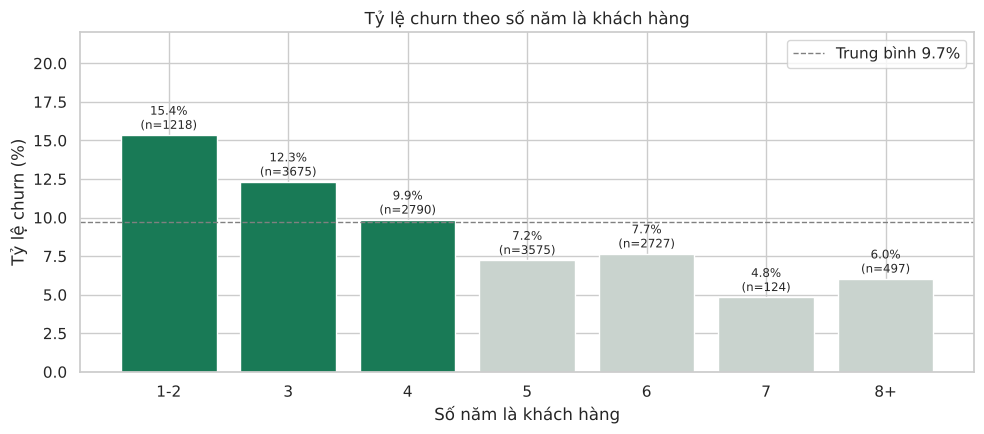

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [BLUE if r > churn_rate else GREY for r in tenure['mean']]
ax.bar(tenure.index, tenure['mean'] * 100, color=colors)
ax.axhline(churn_rate * 100, color='grey', linestyle='--', linewidth=1, label=f'Trung bình {churn_rate:.1%}')
for i, (r, n) in enumerate(zip(tenure['mean'], tenure['count'])):
    ax.text(i, r * 100 + 0.4, f'{r:.1%}\n(n={n})', ha='center', fontsize=8.5)
ax.set_title('Tỷ lệ churn theo số năm là khách hàng')
ax.set_xlabel('Số năm là khách hàng')
ax.set_ylabel('Tỷ lệ churn (%)')
ax.set_ylim(0, 22)
ax.legend()
plt.tight_layout()
plt.savefig('figures/tenure.png', dpi=150)
plt.show()

Khách mới churn nhiều hơn hẳn: khách dưới 4 năm churn 12–15%, còn khách từ 5 năm trở lên chỉ khoảng 5–8%. Khách càng gắn bó lâu càng ít rời đi.

### 3.2 Biên lợi nhuận

In [12]:
client['margin_group'] = pd.qcut(client['margin_net_pow_ele'], 5,
                                 labels=['Thấp nhất', 'Thấp', 'Trung bình', 'Cao', 'Cao nhất'])
margin = client.groupby('margin_group', observed=True).agg(
    churn=('churn', 'mean'), count=('churn', 'size'),
    margin_median=('margin_net_pow_ele', 'median'))
margin

,churn,count,margin_median
margin_group,,,
Thấp nhất,0.072667,3000,7.42
Thấp,0.068421,2850,15.92
Trung bình,0.072256,2934,21.64
Cao,0.114286,2905,27.86
Cao nhất,0.158382,2917,39.84


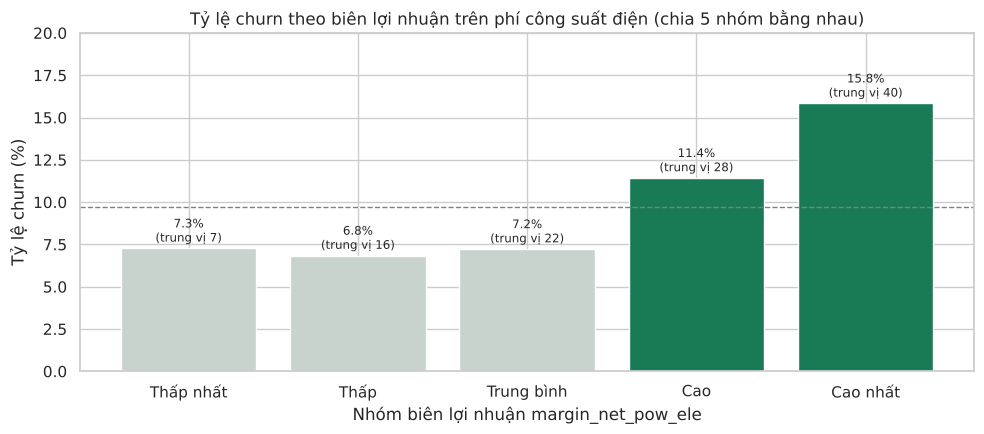

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [BLUE if r > churn_rate else GREY for r in margin['churn']]
ax.bar(margin.index.astype(str), margin['churn'] * 100, color=colors)
ax.axhline(churn_rate * 100, color='grey', linestyle='--', linewidth=1)
for i, (r, m) in enumerate(zip(margin['churn'], margin['margin_median'])):
    ax.text(i, r * 100 + 0.4, f'{r:.1%}\n(trung vị {m:.0f})', ha='center', fontsize=8.5)
ax.set_title('Tỷ lệ churn theo biên lợi nhuận trên phí công suất điện (chia 5 nhóm bằng nhau)')
ax.set_xlabel('Nhóm biên lợi nhuận margin_net_pow_ele')
ax.set_ylabel('Tỷ lệ churn (%)')
ax.set_ylim(0, 20)
plt.tight_layout()
plt.savefig('figures/margin.png', dpi=150)
plt.show()

Đây là yếu tố có quan hệ rõ nhất: 20% khách mà PowerCo có biên lợi nhuận trên phí công suất cao nhất churn 15,8%, gấp đôi nhóm thấp nhất (7,3%). Nói cách khác, những khách đang "đem lại nhiều lãi" nhất trên phần phí công suất lại là những khách dễ rời đi nhất. Có thể họ đang bị tính phí công suất cao hơn mặt bằng thị trường.

### 3.3 Kênh bán hàng và chương trình gốc

Hai cột này đã bị mã hóa (tên là chuỗi ký tự ngẫu nhiên), nên mình chỉ đặt tên lại là Kênh A, B, C... theo số lượng khách.

In [14]:
channel_names = {name: f'Kênh {chr(65 + i)}' for i, name in
                 enumerate(client.loc[client.channel_sales != 'MISSING', 'channel_sales'].value_counts().index)}
channel_names['MISSING'] = 'Không rõ'
client['channel'] = client['channel_sales'].map(channel_names)

origin_names = {name: f'Gói {i + 1}' for i, name in
                enumerate(client.loc[client.origin_up != 'MISSING', 'origin_up'].value_counts().index)}
origin_names['MISSING'] = 'Không rõ'
client['origin'] = client['origin_up'].map(origin_names)

channel = client.groupby('channel')['churn'].agg(['mean', 'count'])
origin = client.groupby('origin')['churn'].agg(['mean', 'count'])
print(channel[channel['count'] > 100].sort_values('mean', ascending=False).round(3))
print(origin[origin['count'] > 100].sort_values('mean', ascending=False).round(3))

           mean  count
channel               
Kênh A    0.121   6754
Kênh C    0.100   1375
Kênh D    0.084    893
Không rõ  0.076   3725
Kênh B    0.056   1843
         mean  count
origin              
Gói 1   0.126   7097
Gói 3   0.084   3148
Gói 2   0.060   4294


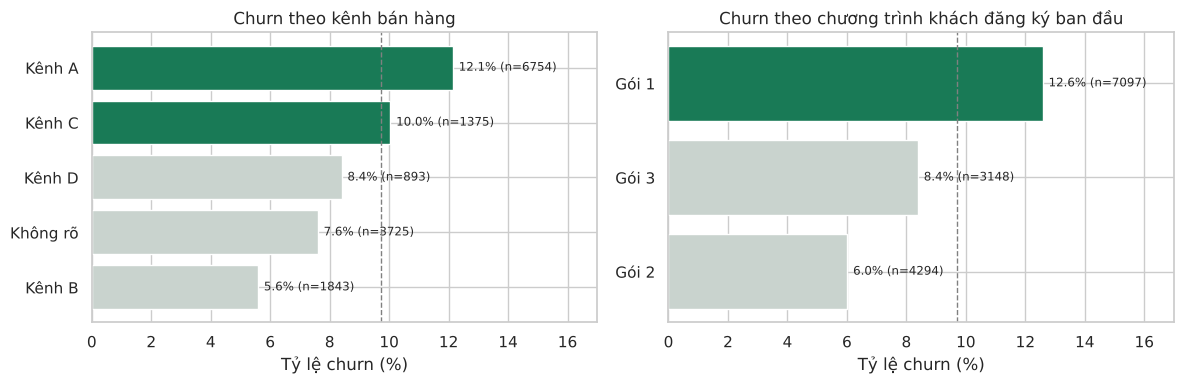

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ch = channel[channel['count'] > 100].sort_values('mean')
axes[0].barh(ch.index, ch['mean'] * 100, color=[BLUE if r > churn_rate else GREY for r in ch['mean']])
axes[0].set_title('Churn theo kênh bán hàng')
og = origin[origin['count'] > 100].sort_values('mean')
axes[1].barh(og.index, og['mean'] * 100, color=[BLUE if r > churn_rate else GREY for r in og['mean']])
axes[1].set_title('Churn theo chương trình khách đăng ký ban đầu')
for ax, tab in [(axes[0], ch), (axes[1], og)]:
    ax.axvline(churn_rate * 100, color='grey', linestyle='--', linewidth=1)
    for i, (r, n) in enumerate(zip(tab['mean'], tab['count'])):
        ax.text(r * 100 + 0.2, i, f'{r:.1%} (n={n})', va='center', fontsize=8.5)
    ax.set_xlabel('Tỷ lệ churn (%)')
    ax.set_xlim(0, 17)
plt.tight_layout()
plt.savefig('figures/channel_origin.png', dpi=150)
plt.show()

- Kênh A (kênh lớn nhất, 6.754 khách) churn 12,1%, cao gấp đôi kênh B (5,6%).
- Gói 1 (7.097 khách) churn 12,6%, gấp đôi gói 2 (6,0%).

Không biết tên thật của các kênh và gói, nhưng PowerCo nên kiểm tra kênh A và gói 1 đang hứa hẹn gì với khách lúc ký hợp đồng.

Các yếu tố khác (có dùng gas hay không, số sản phẩm đang dùng, mức tiêu thụ) chênh lệch ít:

In [16]:
print(client.groupby('has_gas')['churn'].agg(['mean', 'count']).round(3))
print(client.groupby(client['nb_prod_act'].clip(upper=3))['churn'].agg(['mean', 'count']).round(3))
print(client.groupby(pd.qcut(client['cons_12m'], 5))['churn'].mean().round(3))

          mean  count
has_gas              
f        0.101  11955
t        0.082   2651
              mean  count
nb_prod_act              
1            0.100  11431
2            0.085   2445
3            0.096    730
cons_12m
(-0.001, 4517.0]        0.094
(4517.0, 9898.0]        0.096
(9898.0, 20444.0]       0.101
(20444.0, 55292.0]      0.111
(55292.0, 6207104.0]    0.084
Name: churn, dtype: float64


## 4. Kiểm tra giả thuyết: khách rời đi vì giá?

### 4.1 Tạo các biến về giá

Từ bảng `price` (giá theo tháng trong năm 2015), mình tính cho mỗi khách:
- Giá điện trung bình năm 2015 (phần theo lượng dùng và phần cố định, giờ thấp điểm)
- Mức thay đổi giá từ tháng 1 đến tháng 12/2015
- Độ biến động giá trong năm (độ lệch chuẩn)

In [17]:
price = price.sort_values(['id', 'price_date'])
grp = price.groupby('id')

price_feat = pd.DataFrame({
    'price_var_mean': grp['price_off_peak_var'].mean(),
    'price_fix_mean': grp['price_off_peak_fix'].mean(),
    'price_var_change': grp['price_off_peak_var'].last() - grp['price_off_peak_var'].first(),
    'price_fix_change': grp['price_off_peak_fix'].last() - grp['price_off_peak_fix'].first(),
    'price_var_std': grp['price_off_peak_var'].std(),
}).reset_index()

df = client.merge(price_feat, on='id', how='left')
price_feat.describe().round(4)

,price_var_mean,price_fix_mean,price_var_change,price_fix_change,price_var_std
count,16096.0000,16096.0000,16096.0000,16096.0000,16096.0000
mean,0.1410,43.3348,-0.0045,0.2795,0.0042
std,0.0242,5.3425,0.0128,1.4328,0.0052
min,0.0000,0.0000,-0.1485,-44.2669,0.0000
25%,0.1241,40.6882,-0.0082,0.0000,0.0022
50%,0.1473,44.2817,-0.0056,0.1629,0.0032
75%,0.1502,44.3706,-0.0036,0.1778,0.0043
max,0.2788,59.4447,0.1690,40.7289,0.0690


Trong năm 2015, giá điện theo lượng dùng của gần như mọi khách đều **giảm**:

In [18]:
print(f"Giá theo lượng dùng giảm: {(df['price_var_change'] < 0).mean():.1%} khách")
print(f"Giá theo lượng dùng tăng: {(df['price_var_change'] > 0).mean():.1%} khách")
print(f"Phí cố định tăng:         {(df['price_fix_change'] > 0).mean():.1%} khách")
df.groupby(np.sign(df['price_var_change'].round(4)))['churn'].agg(['mean', 'count']).round(3)

Giá theo lượng dùng giảm: 95.0% khách
Giá theo lượng dùng tăng: 4.4% khách
Phí cố định tăng:         77.1% khách


,mean,count
price_var_change,,
-1.0,0.097,13870
0.0,0.009,111
1.0,0.117,625


95% khách được giảm giá điện trong năm 2015 mà vẫn churn 9,7%. 4% khách bị tăng giá churn 11,7%, cao hơn một chút nhưng nhóm này rất nhỏ (625 khách).

### 4.2 Churn theo mức giá

In [19]:
price_cols = {'price_var_mean': 'Giá điện TB (theo lượng dùng)',
              'price_fix_mean': 'Phí cố định TB',
              'price_var_change': 'Thay đổi giá T1 → T12',
              'margin_net_pow_ele': 'Biên lợi nhuận phí công suất'}
rows = {}
for col, name in price_cols.items():
    q = pd.qcut(df[col].rank(method='first'), 5, labels=['Q1\nthấp nhất', 'Q2', 'Q3', 'Q4', 'Q5\ncao nhất'])
    rows[name] = df.groupby(q, observed=True)['churn'].mean() * 100
price_churn = pd.DataFrame(rows)
price_churn.round(1)

,Giá điện TB (theo lượng dùng),Phí cố định TB,Thay đổi giá T1 → T12,Biên lợi nhuận phí công suất
Q1\nthấp nhất,10.6,11.0,11.0,7.4
Q2,11.8,10.9,10.9,6.7
Q3,8.4,8.6,8.8,7.3
Q4,9.0,7.6,9.1,11.4
Q5\ncao nhất,8.8,10.4,8.8,15.9


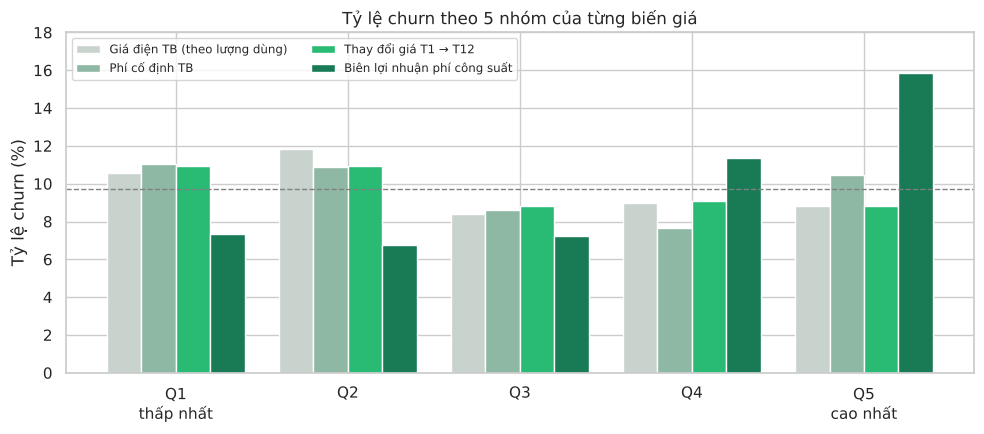

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(5)
w = 0.2
colors = [GREY, '#8FB8A4', MINT, BLUE]
for i, (name, color) in enumerate(zip(price_churn.columns, colors)):
    ax.bar(x + (i - 1.5) * w, price_churn[name], width=w, color=color, label=name)
ax.axhline(churn_rate * 100, color='grey', linestyle='--', linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(price_churn.index)
ax.set_title('Tỷ lệ churn theo 5 nhóm của từng biến giá')
ax.set_ylabel('Tỷ lệ churn (%)')
ax.set_ylim(0, 18)
ax.legend(fontsize=8.5, ncol=2)
plt.tight_layout()
plt.savefig('figures/price_test.png', dpi=150)
plt.show()

In [21]:
for col in ['price_var_mean', 'price_fix_mean', 'price_var_change', 'price_fix_change', 'price_var_std', 'margin_net_pow_ele']:
    print(f'Tương quan {col:20s} với churn: {df[col].corr(df["churn"]):+.3f}')

Tương quan price_var_mean       với churn: -0.006
Tương quan price_fix_mean       với churn: +0.017
Tương quan price_var_change     với churn: -0.001
Tương quan price_fix_change     với churn: +0.003
Tương quan price_var_std        với churn: +0.037
Tương quan margin_net_pow_ele   với churn: +0.096


Kết quả:
- Giá điện, phí cố định và mức thay đổi giá: tỷ lệ churn dao động quanh 8–12% ở mọi mức giá, không có xu hướng "giá càng cao càng churn". Tương quan gần như bằng 0.
- Chỉ có biên lợi nhuận trên phí công suất là tăng rõ theo nhóm.

**Kết luận giả thuyết:** dữ liệu **không ủng hộ** việc giá điện là nguyên nhân chính khiến khách rời đi. Nếu có yếu tố "giá" thì nó nằm ở phí công suất (thể hiện qua biên lợi nhuận) chứ không phải giá điện. Mục 5 sẽ kiểm tra lại bằng mô hình.

## 5. Feature engineering

Thêm các biến về thời gian, tính theo tháng tính đến 01/01/2016:

In [22]:
df['tenure_months'] = (ref_date - df['date_activ']).dt.days / 30.4
df['months_to_end'] = (df['date_end'] - ref_date).dt.days / 30.4
df['months_since_modif'] = (ref_date - df['date_modif_prod']).dt.days / 30.4
df['months_since_renewal'] = (ref_date - df['date_renewal']).dt.days / 30.4
df['has_gas'] = (df['has_gas'] == 't').astype(int)

print('margin_gross_pow_ele = margin_net_pow_ele ở', f"{(df['margin_gross_pow_ele'] == df['margin_net_pow_ele']).mean():.2%}", 'số dòng')

margin_gross_pow_ele = margin_net_pow_ele ở 99.99% số dòng


`margin_gross_pow_ele` và `margin_net_pow_ele` giống nhau ở 99,99% số dòng nên bỏ một cột. Các cột ngày gốc thay bằng số tháng, kênh bán và gói gốc chuyển thành biến 0/1 (one-hot).

In [23]:
model_df = pd.get_dummies(df, columns=['channel', 'origin'], dtype=int)
drop_cols = ['id', 'churn', 'channel_sales', 'origin_up', 'margin_gross_pow_ele', 'margin_group',
             'tenure_years'] + date_cols
X = model_df.drop(columns=drop_cols)
y = model_df['churn']
print(X.shape)
list(X.columns)

(14606, 40)


['cons_12m',
 'cons_gas_12m',
 'cons_last_month',
 'forecast_cons_12m',
 'forecast_cons_year',
 'forecast_discount_energy',
 'forecast_meter_rent_12m',
 'forecast_price_energy_off_peak',
 'forecast_price_energy_peak',
 'forecast_price_pow_off_peak',
 'has_gas',
 'imp_cons',
 'margin_net_pow_ele',
 'nb_prod_act',
 'net_margin',
 'num_years_antig',
 'pow_max',
 'price_var_mean',
 'price_fix_mean',
 'price_var_change',
 'price_fix_change',
 'price_var_std',
 'tenure_months',
 'months_to_end',
 'months_since_modif',
 'months_since_renewal',
 'channel_Không rõ',
 'channel_Kênh A',
 'channel_Kênh B',
 'channel_Kênh C',
 'channel_Kênh D',
 'channel_Kênh E',
 'channel_Kênh F',
 'channel_Kênh G',
 'origin_Gói 1',
 'origin_Gói 2',
 'origin_Gói 3',
 'origin_Gói 4',
 'origin_Gói 5',
 'origin_Không rõ']

## 6. Mô hình dự đoán churn

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, f'churn {y_train.mean():.1%}')
print('Test: ', X_test.shape, f'churn {y_test.mean():.1%}')

rf = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
prob = rf.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)

print(f'Accuracy:  {accuracy_score(y_test, pred):.3f}')
print(f'Precision: {precision_score(y_test, pred):.3f}')
print(f'Recall:    {recall_score(y_test, pred):.3f}')
print(f'F1:        {f1_score(y_test, pred):.3f}')
print(f'AUC:       {roc_auc_score(y_test, prob):.3f}')
print(f'Accuracy nếu đoán tất cả là "ở lại": {1 - y_test.mean():.3f}')

Train: (10954, 40) churn 9.7%
Test:  (3652, 40) churn 9.7%


Accuracy:  0.909
Precision: 0.839
Recall:    0.073
F1:        0.135
AUC:       0.706
Accuracy nếu đoán tất cả là "ở lại": 0.903


**Cẩn thận với accuracy 90,9%.** Nếu đoán tất cả khách đều ở lại thì accuracy đã là 90,3%. Mô hình chỉ hơn mốc này 0,6 điểm. Ở ngưỡng mặc định 0,5, mô hình chỉ bắt được **7% số khách rời đi** (recall). Nhiều bài làm case này chỉ báo cáo accuracy 90% và precision cao, nhưng như vậy là gần như vô dụng cho việc giữ chân khách.

Hạ ngưỡng xuống thì bắt được nhiều hơn, đổi lại có nhiều cảnh báo nhầm hơn:

In [25]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15]:
    p = (prob >= t).astype(int)
    rows.append({'Ngưỡng': t, 'Số khách bị cảnh báo': p.sum(),
                 'Precision': precision_score(y_test, p), 'Recall': recall_score(y_test, p)})
pd.DataFrame(rows).round(3)

,Ngưỡng,Số khách bị cảnh báo,Precision,Recall
0,0.50,31,0.839,0.073
1,0.40,59,0.661,0.110
2,0.30,156,0.410,0.180
3,0.20,481,0.266,0.361
4,0.15,867,0.216,0.527


Cách dùng hợp lý hơn là **xếp hạng** khách theo xác suất rời đi rồi chăm sóc nhóm đầu danh sách:

In [26]:
test = df.loc[X_test.index, ['churn', 'net_margin', 'forecast_cons_12m',
                             'forecast_price_energy_off_peak', 'forecast_meter_rent_12m']].copy()
test['risk'] = prob
test = test.sort_values('risk', ascending=False)

for pct in [0.05, 0.10, 0.20, 0.30]:
    top = test.head(int(len(test) * pct))
    print(f'Top {pct:.0%} rủi ro cao ({len(top)} khách): tỷ lệ churn {top["churn"].mean():.1%}, '
          f'bắt được {top["churn"].sum() / test["churn"].sum():.0%} khách rời đi')

Top 5% rủi ro cao (182 khách): tỷ lệ churn 37.9%, bắt được 19% khách rời đi
Top 10% rủi ro cao (365 khách): tỷ lệ churn 28.8%, bắt được 30% khách rời đi
Top 20% rủi ro cao (730 khách): tỷ lệ churn 22.9%, bắt được 47% khách rời đi
Top 30% rủi ro cao (1095 khách): tỷ lệ churn 19.4%, bắt được 60% khách rời đi


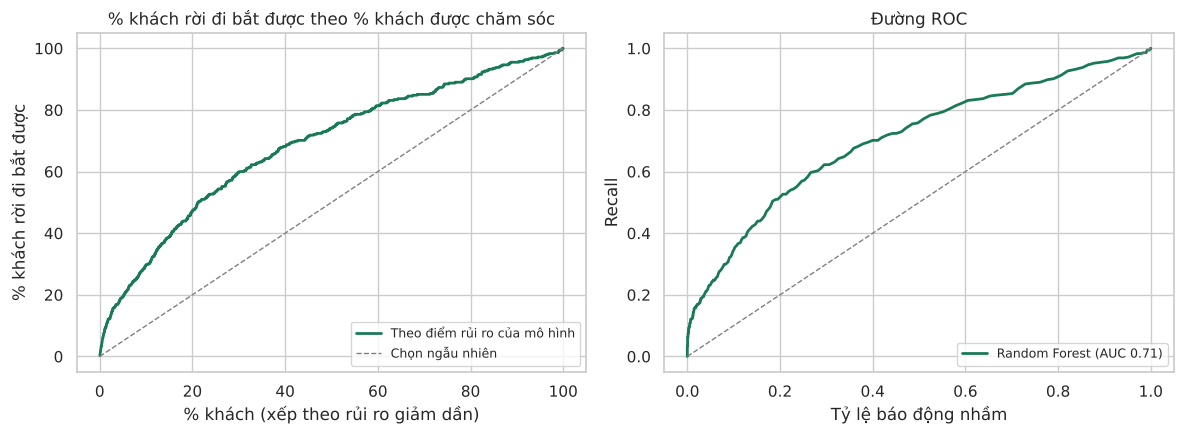

In [27]:
pcts = np.arange(1, len(test) + 1) / len(test) * 100
captured = test['churn'].cumsum() / test['churn'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(pcts, captured, color=BLUE, linewidth=2, label='Theo điểm rủi ro của mô hình')
axes[0].plot([0, 100], [0, 100], color='grey', linestyle='--', linewidth=1, label='Chọn ngẫu nhiên')
axes[0].set_title('% khách rời đi bắt được theo % khách được chăm sóc')
axes[0].set_xlabel('% khách (xếp theo rủi ro giảm dần)')
axes[0].set_ylabel('% khách rời đi bắt được')
axes[0].legend(loc='lower right', fontsize=9)

fpr, tpr, _ = roc_curve(y_test, prob)
axes[1].plot(fpr, tpr, color=BLUE, linewidth=2, label=f'Random Forest (AUC {roc_auc_score(y_test, prob):.2f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=1)
axes[1].set_title('Đường ROC')
axes[1].set_xlabel('Tỷ lệ báo động nhầm')
axes[1].set_ylabel('Recall')
axes[1].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('figures/model.png', dpi=150)
plt.show()

Top 10% khách có rủi ro cao nhất churn 29%, gấp 3 lần mức trung bình; top 5% churn 38%. Mô hình có ích để khoanh vùng, nhưng AUC 0,71 cho thấy dữ liệu hiện có chỉ giải thích được một phần lý do khách rời đi.

### 6.1 Yếu tố nào quan trọng?

In [28]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(15).round(3)

margin_net_pow_ele         0.067
cons_12m                   0.061
forecast_meter_rent_12m    0.061
net_margin                 0.060
tenure_months              0.059
forecast_cons_12m          0.055
months_to_end              0.052
months_since_modif         0.051
price_var_std              0.049
price_var_mean             0.048
months_since_renewal       0.047
pow_max                    0.044
cons_last_month            0.042
price_var_change           0.040
imp_cons                   0.034
dtype: float64

Importance của Random Forest có một điểm yếu: nó hay đánh giá cao các biến số liên tục có nhiều giá trị khác nhau (như giá điện), kể cả khi biến đó không giúp dự đoán. Vì vậy mình kiểm tra thêm bằng cách **bỏ từng nhóm biến ra rồi huấn luyện lại**: nhóm nào thật sự quan trọng thì bỏ đi AUC sẽ giảm.

In [29]:
price_features = ['price_var_mean', 'price_fix_mean', 'price_var_change', 'price_fix_change', 'price_var_std',
                  'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak']
groups = {
    'Giá điện': price_features,
    'Biên lợi nhuận': ['margin_net_pow_ele', 'net_margin'],
    'Mức tiêu thụ': ['cons_12m', 'cons_gas_12m', 'cons_last_month', 'forecast_cons_12m', 'forecast_cons_year', 'imp_cons'],
    'Thời gian hợp đồng': ['tenure_months', 'months_to_end', 'months_since_modif', 'months_since_renewal', 'num_years_antig'],
    'Phí công tơ, công suất': ['forecast_meter_rent_12m', 'pow_max'],
    'Kênh bán, gói gốc': [c for c in X.columns if c.startswith(('channel_', 'origin_'))],
}

base_auc = roc_auc_score(y_test, prob)
rows = []
for name, cols in groups.items():
    m = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
    m.fit(X_train.drop(columns=cols), y_train)
    auc = roc_auc_score(y_test, m.predict_proba(X_test.drop(columns=cols))[:, 1])
    rows.append({'Nhóm biến': name, 'Số biến': len(cols), 'Importance cộng lại': importance[cols].sum(),
                 'AUC khi bỏ nhóm': auc, 'AUC giảm': base_auc - auc})
drop_test = pd.DataFrame(rows).set_index('Nhóm biến').sort_values('AUC giảm', ascending=False)
print(f'AUC đầy đủ: {base_auc:.3f}')
drop_test.round(3)

AUC đầy đủ: 0.706


,Số biến,Importance cộng lại,AUC khi bỏ nhóm,AUC giảm
Nhóm biến,,,,
Biên lợi nhuận,2,0.126,0.642,0.064
Mức tiêu thụ,6,0.240,0.687,0.018
Thời gian hợp đồng,5,0.225,0.699,0.007
"Phí công tơ, công suất",2,0.105,0.703,0.003
Giá điện,8,0.249,0.707,-0.001
"Kênh bán, gói gốc",14,0.039,0.707,-0.002


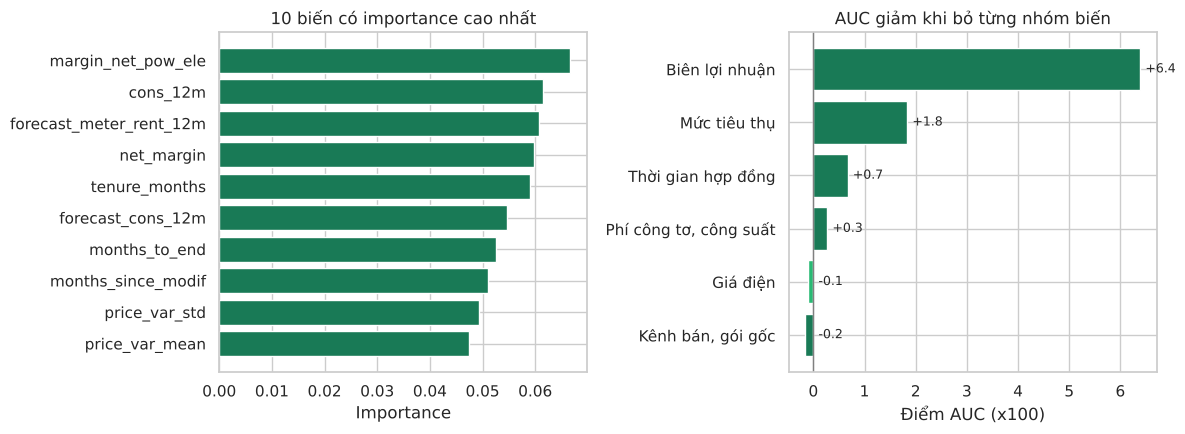

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top_imp = importance.head(10).sort_values()
axes[0].barh(top_imp.index, top_imp.values, color=BLUE)
axes[0].set_title('10 biến có importance cao nhất')
axes[0].set_xlabel('Importance')

dt = drop_test.sort_values('AUC giảm')
axes[1].barh(dt.index, dt['AUC giảm'] * 100, color=[MINT if g == 'Giá điện' else BLUE for g in dt.index])
for i, v in enumerate(dt['AUC giảm']):
    axes[1].text(max(v, 0) * 100 + 0.1, i, f'{v * 100:+.1f}', va='center', fontsize=9)
axes[1].axvline(0, color='grey', linewidth=1)
axes[1].set_title('AUC giảm khi bỏ từng nhóm biến')
axes[1].set_xlabel('Điểm AUC (x100)')
plt.tight_layout()
plt.savefig('figures/importance.png', dpi=150)
plt.show()

Hai cách đo cho kết quả khác nhau, và đây là điểm quan trọng của cả bài:
- Theo importance, 8 biến giá cộng lại chiếm khoảng 25%, nhiều nhất trong các nhóm.
- Nhưng **bỏ hết biến giá ra thì AUC không giảm**. Mô hình có dùng các biến giá để chia nhánh, nhưng chúng không thêm thông tin mới.
- Nhóm quan trọng nhất thật sự là **biên lợi nhuận**: chỉ có 2 biến nhưng bỏ đi thì AUC giảm từ 0,71 xuống 0,64. Tiếp theo là mức tiêu thụ (giảm 0,02) và thời gian hợp đồng (giảm 0,01).
- Kênh bán và gói gốc cũng không làm AUC giảm, có thể vì khác biệt giữa các kênh đã được thể hiện qua biên lợi nhuận và thời gian hợp đồng.

Nếu chỉ nhìn biểu đồ importance như nhiều bài làm case này, dễ kết luận sai rằng "giá là yếu tố quan trọng".

## 7. Giảm giá 20% có đáng không?

Mình ước tính chi phí và lợi ích trên tập test (3.652 khách):
- **Chi phí** = 20% doanh thu dự kiến 12 tháng của khách được giảm giá. Doanh thu ước tính = tiêu thụ dự kiến × giá điện dự kiến + phí thuê công tơ. Con số này chưa gồm phí công suất nên là **ước tính thấp**, chi phí thật còn cao hơn.
- **Lợi ích tối đa** = net margin của những khách sẽ rời đi trong nhóm được giảm giá, giả sử giảm giá giữ lại được **100%** số khách này (rất lạc quan).

In [31]:
test['revenue_est'] = test['forecast_cons_12m'] * test['forecast_price_energy_off_peak'] + test['forecast_meter_rent_12m']

rows = []
for pct in [0.05, 0.10, 0.20, 0.30, 1.0]:
    top = test.head(int(len(test) * pct))
    cost = 0.2 * top['revenue_est'].sum()
    benefit = top.loc[top['churn'] == 1, 'net_margin'].sum()
    rows.append({'Nhóm được giảm giá': 'Tất cả khách' if pct == 1 else f'Top {pct:.0%} rủi ro',
                 'Số khách': len(top), 'Số khách sẽ rời đi': top['churn'].sum(),
                 'Chi phí giảm giá': round(cost), 'Margin giữ lại tối đa': round(benefit),
                 'Lãi/lỗ tối đa': round(benefit - cost)})
discount = pd.DataFrame(rows).set_index('Nhóm được giảm giá')
discount

,Số khách,Số khách sẽ rời đi,Chi phí giảm giá,Margin giữ lại tối đa,Lãi/lỗ tối đa
Nhóm được giảm giá,,,,,
Top 5% rủi ro,182,69,13621,14301,681
Top 10% rủi ro,365,105,28398,21327,-7071
Top 20% rủi ro,730,167,57040,37939,-19101
Top 30% rủi ro,1095,212,82234,47755,-34479
Tất cả khách,3652,355,227755,72193,-155562


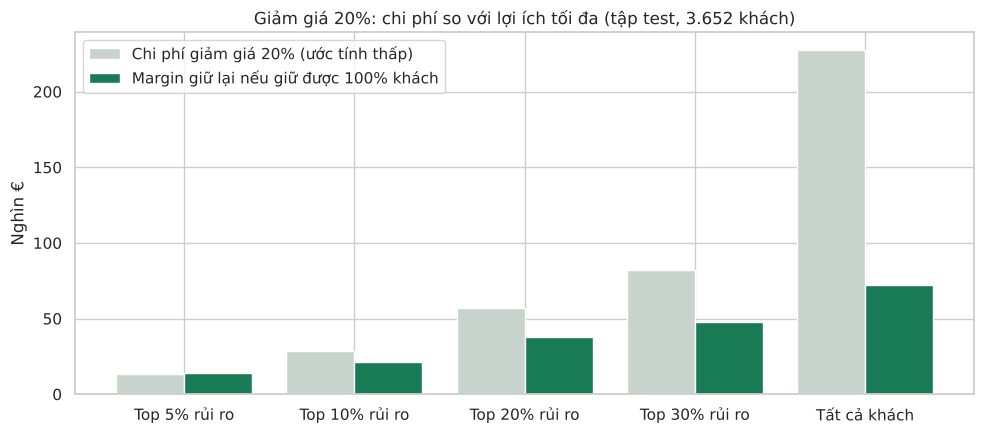

In [32]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(discount))
ax.bar(x - 0.2, discount['Chi phí giảm giá'] / 1000, width=0.4, color=GREY, label='Chi phí giảm giá 20% (ước tính thấp)')
ax.bar(x + 0.2, discount['Margin giữ lại tối đa'] / 1000, width=0.4, color=BLUE, label='Margin giữ lại nếu giữ được 100% khách')
ax.set_xticks(x)
ax.set_xticklabels(discount.index)
ax.set_ylabel('Nghìn €')
ax.set_title('Giảm giá 20%: chi phí so với lợi ích tối đa (tập test, 3.652 khách)')
ax.legend()
plt.tight_layout()
plt.savefig('figures/discount.png', dpi=150)
plt.show()

Kể cả khi giả sử giảm giá giữ chân được **toàn bộ** khách sắp rời đi:
- Giảm cho tất cả khách: chi phí gấp hơn 3 lần lợi ích.
- Giảm cho top 10–30% rủi ro: vẫn lỗ.
- Chỉ top 5% rủi ro cao nhất là gần hòa vốn, và chỉ khi giữ được khoảng 95% số khách rời đi trong nhóm này, điều khó xảy ra.

Lý do: 60–70% khách trong nhóm rủi ro cao vẫn sẽ ở lại dù không được giảm giá, nên phần lớn tiền giảm giá rơi vào những khách không cần. Thêm nữa, phân tích ở mục 4 cho thấy giá không phải lý do chính khiến khách rời đi, nên giảm giá chưa chắc đã giữ được họ.

## 8. Kết luận và đề xuất

**1. Ai đang rời đi?** 9,7% khách rời đi trong 3 tháng. Rủi ro cao hơn ở khách mới (dưới 4 năm: 12–15%), khách có biên lợi nhuận phí công suất cao (15,8%), khách từ kênh A và gói 1 (khoảng 12%).

**2. Có phải vì giá?** Không rõ ràng. Churn gần như không đổi theo giá điện hay mức thay đổi giá. Bỏ toàn bộ biến giá ra khỏi mô hình thì AUC không giảm.

**3. Có nên giảm giá 20%?** Không nên giảm đại trà. Ngay cả trong kịch bản tốt nhất, giảm giá cho hơn 5% khách đã lỗ.

| Đề xuất | Dựa trên |
|---|---|
| Không áp dụng giảm giá 20% đại trà. Nếu thử, chỉ thử trên top 5% rủi ro và có nhóm đối chứng | Chi phí lớn hơn lợi ích ở mọi nhóm rộng hơn 5% |
| Xem lại phí công suất cho nhóm có biên lợi nhuận cao nhất, cân nhắc ưu đãi nhỏ hơn và có mục tiêu | Nhóm này churn 15,8%, gấp đôi nhóm thấp nhất; biên lợi nhuận là nhóm biến quan trọng nhất của mô hình |
| Chương trình chăm sóc khách trong 4 năm đầu | Khách dưới 4 năm churn 12–15% |
| Kiểm tra cam kết bán hàng của kênh A và gói 1 | Churn gấp đôi các kênh, gói khác |
| Thu thập thêm dữ liệu: lý do rời đi, khiếu nại, giá của đối thủ | Mô hình chỉ đạt AUC 0,71, còn thiếu thông tin |

**Hạn chế:** chỉ có 3 tháng quan sát churn; không có giá của đối thủ; doanh thu là ước tính thấp; kênh bán và gói bị mã hóa nên không biết tên thật.